# Google Trends: before, during, and after the peak

Four search terms in the Philippines. Find the peak, compare nearby weeks, then check regions.

Run top to bottom. Dates are fixed to match the original notebook; change `END_DATE` for a newer run.


## 1. Setup

Run this once if the packages are missing.


In [1]:
# Packages are already installed in the repository .venv.
# For a fresh environment, uncomment and run these in the selected kernel:
# %pip install --upgrade pip
# %pip install "numpy>=2.0,<3" "pandas>=2.2,<4" "matplotlib>=3.9,<4" pytrends==4.9.2 "ipykernel>=6.29,<8" "scikit-learn>=1.6,<2"
# %pip install torch==2.13.0 --index-url https://download.pytorch.org/whl/cu130
# Restart the kernel after installation, then run from the top.


In [2]:
import csv
import io
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

try:
    from pytrends.request import TrendReq
    PYTRENDS_AVAILABLE = True
except ImportError:
    PYTRENDS_AVAILABLE = False
    print("pytrends is missing. Install it above, or use manual CSV exports.")


### GPU setup and verification

Select **Tagatrend GPU (.venv)** in the kernel picker. All ML code lives in this notebook.
The setup cell above installs into the selected kernel's Python environment.

The RTX 5050 uses Blackwell compute capability 12.0. PyTorch 2.13.0's CUDA 13.0
Windows wheel supports it, and your installed NVIDIA driver is 610.71. The CUDA
number in `nvidia-smi` describes driver compatibility; `torch.version.cuda` describes
the wheel's runtime. These prebuilt wheels need no separate CUDA Toolkit.
Sources: [PyTorch installation](https://pytorch.org/get-started/previous-versions/),
[Blackwell support](https://pytorch.org/blog/pytorch-2-7/),
[NVIDIA GPU capabilities](https://developer.nvidia.com/cuda/gpus).

The next cell tests actual forward, backward, and optimizer updates on CUDA.
Training requires `cuda:0` and fails clearly if CUDA is unavailable. CSV processing
and Python orchestration use the CPU; ordinary scikit-learn estimators use CPU too.

In [3]:
"""Require CUDA and verify an actual training step, rather than detection alone."""
import json

import torch


def require_cuda():
    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA is unavailable; CPU training is disabled. Use the repository .venv, "
            "run the CUDA installation command in the setup cell, and run nvidia-smi to check the driver."
        )
    return torch.device("cuda:0")


def check_gpu():
    device = require_cuda()
    model = torch.nn.Sequential(torch.nn.Linear(16, 32), torch.nn.ReLU(),
                                torch.nn.Linear(32, 1)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    inputs = torch.randn(64, 16, device=device)
    targets = torch.randn(64, 1, device=device)
    before = model[0].weight.detach().clone()
    for _ in range(3):
        optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.mse_loss(model(inputs), targets)
        loss.backward()
        optimizer.step()
    torch.cuda.synchronize()
    if not torch.isfinite(loss) or torch.equal(before, model[0].weight):
        raise RuntimeError("CUDA training smoke test failed.")
    return {
        "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(device),
        "compute_capability": list(torch.cuda.get_device_capability(device)),
        "compiled_architectures": torch.cuda.get_arch_list(),
        "vram_gib": round(torch.cuda.get_device_properties(device).total_memory / 2**30, 2),
        "model_device": str(next(model.parameters()).device),
        "training_step_passed": True,
    }


import sys
print("Kernel Python:", sys.executable)
gpu_info = check_gpu()
display(pd.Series(gpu_info, name="GPU verification"))

Kernel Python: c:\Users\Admin\OneDrive\Documents\GitHub\tagatrend\.venv\Scripts\python.exe


torch                                                     2.13.0+cu130
cuda_runtime                                                      13.0
gpu                                 NVIDIA GeForce RTX 5050 Laptop GPU
compute_capability                                             [12, 0]
compiled_architectures    [sm_75, sm_80, sm_86, sm_90, sm_100, sm_120]
vram_gib                                                          7.96
model_device                                                    cuda:0
training_step_passed                                              True
Name: GPU verification, dtype: object

In [4]:
GEO = "PH"
END_DATE = "2026-09-25"
REFRESH = False  # True: request fresh data instead of using saved files.
RUN_REGIONS = True

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

trends = pd.DataFrame([
    {"slug": "sana_all", "query": "Sana All", "start": "2018-01-01"},
    {"slug": "pabebe_girls", "query": "Pabebe Girls", "start": "2015-01-01"},
    {"slug": "never_grow_old", "query": "Never Grow Old", "start": "2026-08-15"},
    {"slug": "fox_silica", "query": "Fox Silica", "start": "2026-07-15"},
])
trends["end"] = END_DATE

display(trends[["query", "start", "end"]])


,query,start,end
0,Sana All,2018-01-01,2026-09-25
1,Pabebe Girls,2015-01-01,2026-09-25
2,Never Grow Old,2026-08-15,2026-09-25
3,Fox Silica,2026-07-15,2026-09-25


These are search terms, not confirmed trend origins. Start dates only set the search window.

Scores show relative interest, not search counts. Each request has its own scale. A zero can mean too little data. [Google's guide](https://support.google.com/trends/answer/4365533?hl=en)


## 2. Load the data

Use a matching saved file first, then pytrends, then a manual export.

For manual data, export **Interest over time** or **Interest by subregion** from Google Trends. Match the printed query, PH, and dates. Save to the path printed on failure. Use one search term per export.

Three helpers handle repeated file and request work. The analysis stays in separate cells.


In [5]:
def read_manual_export(path, kind):
    """Skip Google's title rows and read one search term."""
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    header_row = None

    if kind == "time":
        headers = {"date", "day", "week", "month"}
    else:
        headers = {"region", "subregion", "geoname", "country"}

    for row_number, line in enumerate(lines):
        fields = next(csv.reader([line]))
        if fields and fields[0].strip().lower() in headers:
            header_row = row_number
            break

    if header_row is None:
        raise ValueError("No date or region header found. Use an English Google Trends export.")

    frame = pd.read_csv(io.StringIO("\n".join(lines[header_row:])))
    frame = frame.dropna(how="all")
    if len(frame.columns) != 2:
        raise ValueError("Export exactly one search term.")

    frame.columns = ["label", "interest"]
    # Google reports <1 as a range. Use 0.5 as an approximation.
    values = frame["interest"].astype(str).str.strip()
    values = values.replace({"<1": "0.5", "< 1": "0.5"})
    frame["interest"] = pd.to_numeric(values, errors="coerce")

    if kind == "time":
        frame["label"] = pd.to_datetime(frame["label"], errors="raise")
    return frame.set_index("label")


In [6]:
def request_trends(query, window, kind):
    """Retry only when Google rate-limits the request."""
    if not PYTRENDS_AVAILABLE:
        raise RuntimeError("pytrends is not installed")

    for attempt in range(3):
        try:
            client = TrendReq(hl="en-PH", tz=-480, timeout=(10, 30))
            client.build_payload([query], timeframe=window, geo=GEO)

            if kind == "time":
                frame = client.interest_over_time()
            else:
                frame = client.interest_by_region(
                    resolution="REGION", inc_low_vol=True, inc_geo_code=False
                )

            if frame.empty:
                raise ValueError("Google returned no data")
            time.sleep(1)
            return frame
        except Exception as error:
            response = getattr(error, "response", None)
            status = getattr(response, "status_code", None)
            if status == 429 and attempt < 2:
                delay = 5 * (attempt + 1)
                print(f"Rate limit. Trying again in {delay} seconds.")
                time.sleep(delay)
            else:
                raise


In [7]:
def load_trends(slug, query, start, end, kind="time"):
    """Keep each query, date window, and data type in its own cache."""
    window = f"{start} {end}"
    filename = f"{slug}_{kind}_{start}_{end}"
    csv_path = RAW_DIR / f"{filename}.csv"
    json_path = RAW_DIR / f"{filename}.json"
    manual_path = DATA_DIR / f"{filename}.csv"
    expected = {"query": query, "geo": GEO, "window": window, "kind": kind}

    if pd.Timestamp(start) > pd.Timestamp(end):
        raise ValueError("Start date must be on or before the end date.")

    if csv_path.exists() and json_path.exists() and not REFRESH:
        saved = json.loads(json_path.read_text(encoding="utf-8"))
        matches = True
        for key, value in expected.items():
            if saved.get(key) != value:
                matches = False
        if matches:
            print(f"{query}: saved {kind} data ({window})")
            return pd.read_csv(csv_path, index_col=0)

    try:
        frame = request_trends(query, window, kind)
        source = "pytrends"
    except Exception as error:
        print(f"{query}, PH, {window}: {error}")
        if manual_path.exists():
            frame = read_manual_export(manual_path, kind)
            source = "manual CSV"
        else:
            print(f"Save the matching export to: {manual_path}")
            return None

    saved = expected.copy()
    saved["source"] = source
    saved["extracted_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    frame.to_csv(csv_path)
    json_path.write_text(json.dumps(saved, indent=2), encoding="utf-8")
    print(f"{query}: {len(frame)} rows from {source}")
    return frame


In [8]:
raw_data = {}

for trend in trends.itertuples(index=False):
    frame = load_trends(trend.slug, trend.query, trend.start, trend.end)
    if frame is not None:
        raw_data[trend.slug] = frame

if not raw_data:
    print("No data loaded. Add the exports above, then rerun from this cell.")


Sana All: 105 rows from pytrends
Pabebe Girls: 141 rows from pytrends
Never Grow Old: 42 rows from pytrends
Fox Silica: 73 rows from pytrends


## 3. Check coverage and find the peak period

Drop rows Google marks unfinished. Keep missing values as missing.

Monthly rows identify a peak month, not a peak day. If peaks tie, use the earliest one.


In [9]:
data = {}
partial_counts = {}

for trend in trends.itertuples(index=False):
    if trend.slug not in raw_data:
        continue

    frame = raw_data[trend.slug].copy()
    frame.index = pd.to_datetime(frame.index)
    frame = frame.sort_index()
    partial_rows = 0
    if "isPartial" in frame.columns:
        partial = frame["isPartial"].astype(str).str.lower() == "true"
        partial_rows = int(partial.sum())
        frame = frame.loc[~partial].drop(columns="isPartial")

    if len(frame.columns) != 1 or frame.index.has_duplicates:
        print(f"{trend.query}: expected one series with unique dates; skipped.")
        continue

    series = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
    series = series.loc[trend.start:trend.end]
    series = series.where(series.between(0, 100))
    valid = series.dropna()
    if valid.empty:
        print(f"{trend.query}: no usable values.")
        continue

    data[trend.slug] = series
    partial_counts[trend.slug] = partial_rows


In [10]:
peak_periods = {}
overview_rows = []

for trend in trends.itertuples(index=False):
    if trend.slug not in data:
        continue

    series = data[trend.slug]
    valid = series.dropna()
    spacing = series.index.to_series().diff().dt.days.median()
    if spacing == 1:
        frequency = "Daily"
    elif spacing == 7:
        frequency = "Weekly"
    elif 28 <= spacing <= 31:
        frequency = "Monthly"
    else:
        frequency = "Irregular / unknown"

    peak_label = "No positive peak"
    if valid.max() > 0:
        peak_start = valid.idxmax()
        if frequency == "Monthly":
            peak_end = peak_start + pd.DateOffset(months=1) - pd.Timedelta(days=1)
        elif frequency == "Weekly":
            peak_end = peak_start + pd.Timedelta(days=6)
        else:
            peak_end = peak_start

        peak_label = f"{peak_start:%Y-%m-%d} to {peak_end:%Y-%m-%d}"
        if frequency != "Irregular / unknown":
            peak_periods[trend.slug] = (peak_start, peak_end)

    overview_rows.append({
        "Trend": trend.query,
        "Frequency": frequency,
        "First row": f"{series.index.min():%Y-%m-%d}",
        "Last row": f"{series.index.max():%Y-%m-%d}",
        "Missing values": int(series.isna().sum()),
        "Partial rows removed": partial_counts[trend.slug],
        "Peak period": peak_label,
        "Latest score": valid.iloc[-1],
    })

overview = pd.DataFrame(overview_rows)
display(overview)


,Trend,Frequency,First row,Last row,Missing values,Partial rows removed,Peak period,Latest score
0,Sana All,Monthly,2018-01-01,2026-09-01,0,0,2019-11-01 to 2019-11-30,6
1,Pabebe Girls,Monthly,2015-01-01,2026-09-01,0,0,2015-07-01 to 2015-07-31,0
2,Never Grow Old,Daily,2026-08-15,2026-09-25,0,0,2026-09-11 to 2026-09-11,0
3,Fox Silica,Daily,2026-07-15,2026-09-25,0,0,2026-07-29 to 2026-07-29,0


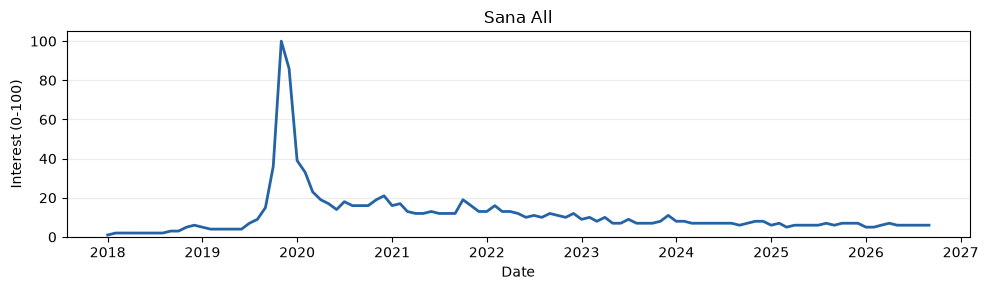

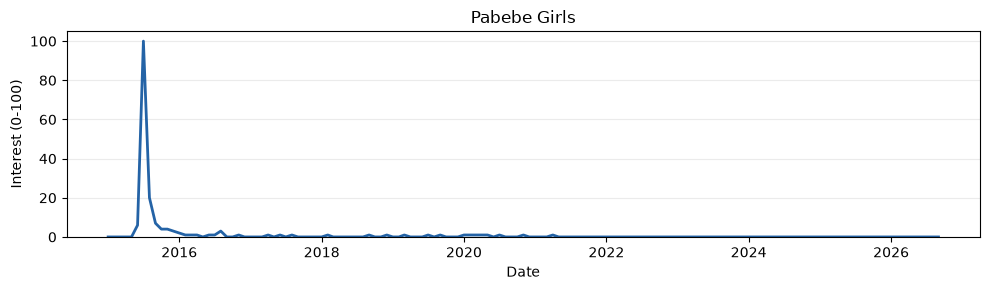

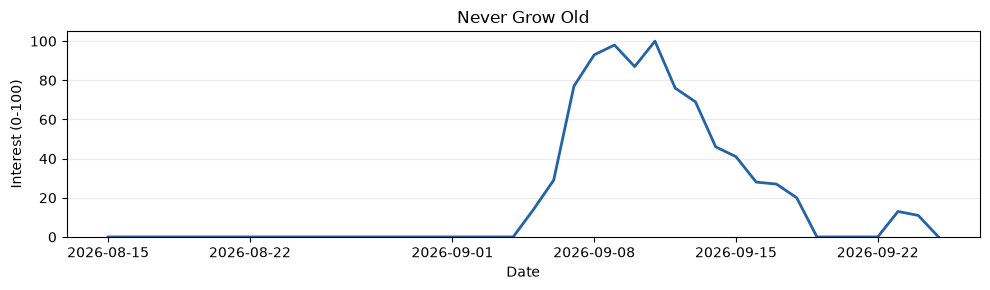

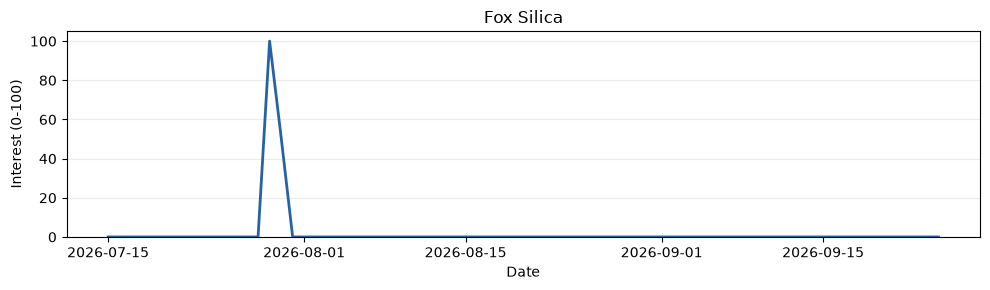

In [11]:
for trend in trends.itertuples(index=False):
    if trend.slug not in data:
        continue

    series = data[trend.slug]
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(series.index, series, color="#2463a6", linewidth=2)
    ax.set(title=trend.query, xlabel="Date", ylabel="Interest (0-100)", ylim=(0, 105))
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()


## 4. Zoom in on the peak

Request daily data around the strongest period, with three weeks on either side.
Find the highest day **inside that period**. This is a local peak; a different month could contain a higher single day.

Use one daily request per trend so nearby weeks share the same scale. Do not compare these scores with the full-history scores.


In [12]:
zoom_data = {}

for trend in trends.itertuples(index=False):
    if trend.slug not in peak_periods:
        continue

    peak_start, peak_end = peak_periods[trend.slug]
    zoom_start = peak_start - pd.Timedelta(days=21)
    zoom_end = peak_end + pd.Timedelta(days=21)
    if zoom_start < pd.Timestamp("2004-01-01"):
        zoom_start = pd.Timestamp("2004-01-01")
    if zoom_end > pd.Timestamp(END_DATE):
        zoom_end = pd.Timestamp(END_DATE)

    frame = load_trends(
        trend.slug, trend.query,
        f"{zoom_start:%Y-%m-%d}", f"{zoom_end:%Y-%m-%d}",
    )
    if frame is not None:
        zoom_data[trend.slug] = frame


Sana All: 72 rows from pytrends
Pabebe Girls: 73 rows from pytrends
Never Grow Old: 36 rows from pytrends
Fox Silica: 43 rows from pytrends


In [13]:
daily_data = {}
peak_days = {}
peak_day_rows = []

for trend in trends.itertuples(index=False):
    if trend.slug not in zoom_data:
        continue

    frame = zoom_data[trend.slug].copy()
    frame.index = pd.to_datetime(frame.index)
    frame = frame.sort_index()
    if "isPartial" in frame.columns:
        partial = frame["isPartial"].astype(str).str.lower() == "true"
        frame = frame.loc[~partial].drop(columns="isPartial")

    if len(frame.columns) != 1 or frame.index.has_duplicates:
        print(f"{trend.query}: expected one daily series with unique dates; skipped.")
        continue

    gaps = frame.index.to_series().diff().dropna()
    if gaps.empty or gaps.median() != pd.Timedelta(days=1):
        print(f"{trend.query}: daily data needed. Weekly or monthly rows cannot fill daily gaps.")
        continue
    if not (frame.index == frame.index.normalize()).all():
        print(f"{trend.query}: expected daily rows, not hourly rows.")
        continue

    series = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
    series = series.where(series.between(0, 100))
    series = series.loc[:END_DATE]
    peak_start, peak_end = peak_periods[trend.slug]
    candidates = series.loc[peak_start:peak_end].dropna()
    if candidates.empty or candidates.max() <= 0:
        print(f"{trend.query}: no positive daily peak in the selected period.")
        continue

    peak_day = candidates.idxmax()
    daily_data[trend.slug] = series
    peak_days[trend.slug] = peak_day
    peak_day_rows.append({
        "Trend": trend.query,
        "Peak day": f"{peak_day:%Y-%m-%d}",
        "Tied peak days": int((candidates == candidates.max()).sum()),
        "Days in peak period": int(candidates.count()),
        "Expected days": (peak_end - peak_start).days + 1,
    })

display(pd.DataFrame(peak_day_rows))


,Trend,Peak day,Tied peak days,Days in peak period,Expected days
0,Sana All,2019-11-17,1,30,30
1,Pabebe Girls,2015-07-12,1,31,31
2,Never Grow Old,2026-09-11,1,1,1
3,Fox Silica,2026-07-29,1,1,1


## 5. EDA: before, peak, and after

- **Before:** the previous Monday-Sunday week.
- **Peak week:** the Monday-Sunday week containing the peak day.
- **After:** the next Monday-Sunday week.

Show a mean only when all seven days are present. Missing days stay missing; they are not zeros.
Manual exports use 0.5 for `<1`. Avoid unfinished periods when exporting.


In [14]:
week_rows = []
week_windows = {}

for trend in trends.itertuples(index=False):
    if trend.slug not in peak_days:
        continue

    series = daily_data[trend.slug]
    peak_day = peak_days[trend.slug]
    monday = peak_day - pd.Timedelta(days=peak_day.weekday())
    windows = [
        ("Before", monday - pd.Timedelta(days=7)),
        ("Peak week", monday),
        ("After", monday + pd.Timedelta(days=7)),
    ]
    week_windows[trend.slug] = windows

    for label, start in windows:
        end = start + pd.Timedelta(days=6)
        expected_dates = pd.date_range(start, end, freq="D")
        week = series.reindex(expected_dates)
        days = int(week.notna().sum())

        if days == 7:
            mean_interest = week.mean()
            status = "Complete"
        else:
            mean_interest = float("nan")
            status = "Incomplete"

        week_rows.append({
            "Trend": trend.query,
            "Week": label,
            "Start": f"{start:%Y-%m-%d}",
            "End": f"{end:%Y-%m-%d}",
            "Days": days,
            "Mean interest": mean_interest,
            "Status": status,
        })

weekly_summary = pd.DataFrame(week_rows)
display(weekly_summary.round(1))


,Trend,Week,Start,End,Days,Mean interest,Status
0,Sana All,Before,2019-11-04,2019-11-10,7,50.1,Complete
1,Sana All,Peak week,2019-11-11,2019-11-17,7,62.6,Complete
2,Sana All,After,2019-11-18,2019-11-24,7,73.6,Complete
3,Pabebe Girls,Before,2015-06-29,2015-07-05,7,13.1,Complete
4,Pabebe Girls,Peak week,2015-07-06,2015-07-12,7,37.9,Complete
5,Pabebe Girls,After,2015-07-13,2015-07-19,7,53.7,Complete
6,Never Grow Old,Before,2026-08-31,2026-09-06,7,6.1,Complete
7,Never Grow Old,Peak week,2026-09-07,2026-09-13,7,85.7,Complete
8,Never Grow Old,After,2026-09-14,2026-09-20,7,23.1,Complete
9,Fox Silica,Before,2026-07-20,2026-07-26,7,0.0,Complete


### How much did interest change?

Changes below are index points, not extra searches. No percentage change is calculated from a zero baseline.


In [15]:
change_rows = []

for trend in trends.itertuples(index=False):
    if weekly_summary.empty:
        break
    weeks = weekly_summary.loc[weekly_summary["Trend"] == trend.query]
    if weeks.empty:
        continue

    means = weeks.set_index("Week")["Mean interest"]
    before = means["Before"]
    peak = means["Peak week"]
    after = means["After"]

    if pd.isna(before) or pd.isna(peak):
        rise = float("nan")
    else:
        rise = peak - before

    if pd.isna(peak) or pd.isna(after):
        later_change = float("nan")
        retained = float("nan")
    else:
        later_change = after - peak
        if peak > 0:
            retained = 100 * after / peak
        else:
            retained = float("nan")

    change_rows.append({
        "Trend": trend.query,
        "Before to peak (points)": rise,
        "Peak to after (points)": later_change,
        "After / peak (%)": retained,
    })

changes = pd.DataFrame(change_rows)
display(changes.round(1))


,Trend,Before to peak (points),Peak to after (points),After / peak (%)
0,Sana All,12.4,11.0,117.6
1,Pabebe Girls,24.7,15.9,141.9
2,Never Grow Old,79.6,-62.6,27.0
3,Fox Silica,21.6,-21.6,0.0


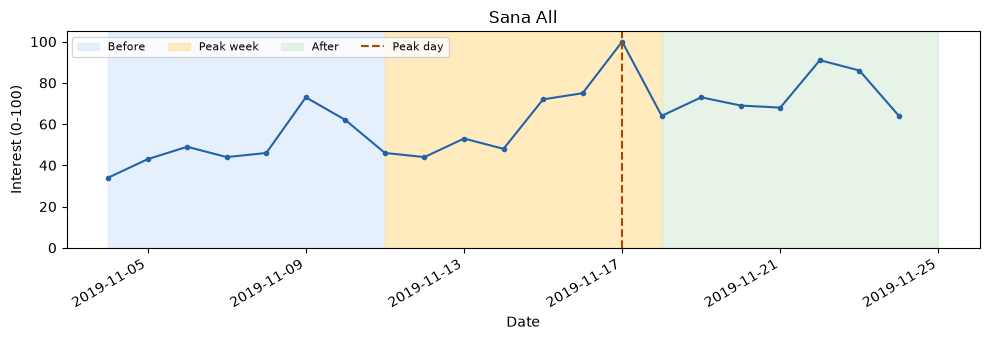

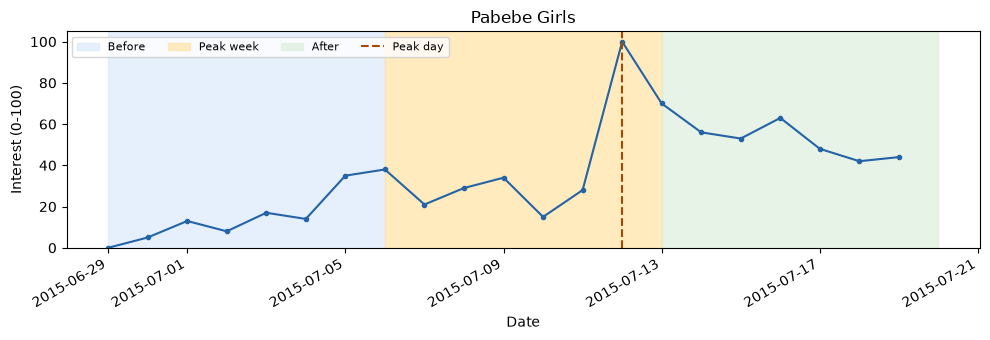

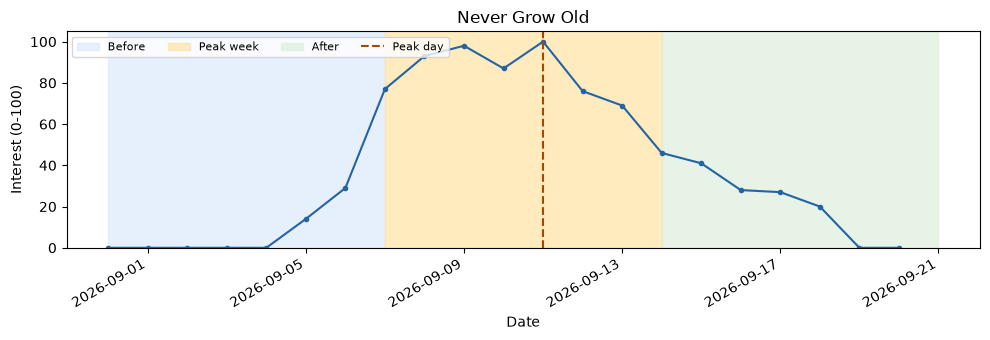

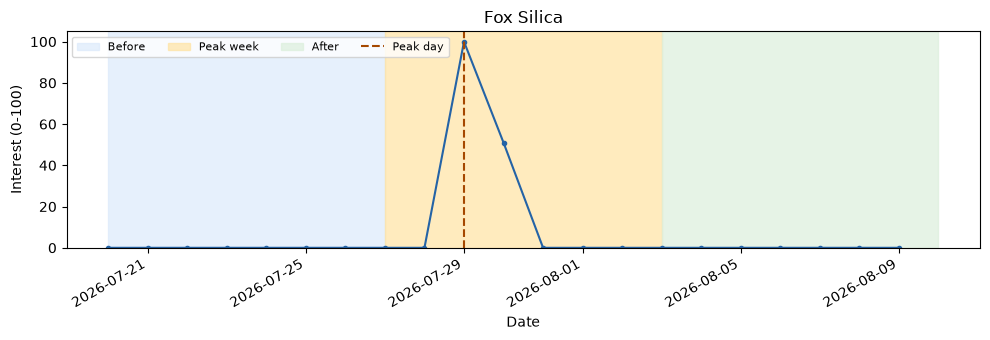

In [16]:
colors = {"Before": "#dceafb", "Peak week": "#ffe3a3", "After": "#dcefdc"}

for trend in trends.itertuples(index=False):
    if trend.slug not in week_windows:
        continue

    windows = week_windows[trend.slug]
    start = windows[0][1]
    end = windows[-1][1] + pd.Timedelta(days=6)
    series = daily_data[trend.slug].reindex(pd.date_range(start, end, freq="D"))

    fig, ax = plt.subplots(figsize=(10, 3.5))
    for label, week_start in windows:
        ax.axvspan(week_start, week_start + pd.Timedelta(days=7),
                   color=colors[label], alpha=0.7, label=label)
    ax.plot(series.index, series, marker="o", markersize=3, color="#2463a6")
    ax.axvline(peak_days[trend.slug], color="#a54800", linestyle="--", label="Peak day")
    ax.set(title=trend.query, xlabel="Date", ylabel="Interest (0-100)", ylim=(0, 105))
    ax.legend(loc="upper left", ncol=4, fontsize=8)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()


## 6. Regional interest

Compare the same three weeks with the last 30 days of the chosen window.
Each panel has its own 0-100 scale. Compare regional ranks, not score changes across panels.
A high score means strong relative interest, not the most searches. [Google's guide](https://support.google.com/trends/answer/4355212?hl=en)

Set `RUN_REGIONS = False` to skip these extra requests.


In [17]:
region_data = {}
region_windows = {}

if RUN_REGIONS:
    for trend in trends.itertuples(index=False):
        if trend.slug not in data:
            continue

        windows = []
        if trend.slug in week_windows:
            for label, start in week_windows[trend.slug]:
                end = start + pd.Timedelta(days=6)
                if end <= pd.Timestamp(END_DATE):
                    windows.append((label, start, end))
                else:
                    print(f"{trend.query}, {label}: week extends beyond END_DATE; skipped.")

        recent_end = pd.Timestamp(END_DATE)
        recent_start = recent_end - pd.Timedelta(days=29)
        windows.append(("Last 30 days", recent_start, recent_end))
        region_windows[trend.slug] = windows

        for label, start, end in windows:
            frame = load_trends(
                trend.slug, trend.query,
                f"{start:%Y-%m-%d}", f"{end:%Y-%m-%d}", kind="region",
            )
            region_data[(trend.slug, label)] = frame
else:
    print("Regional requests skipped.")


Sana All: 17 rows from pytrends
Sana All: 17 rows from pytrends
Sana All: 17 rows from pytrends
Sana All: 17 rows from pytrends
Pabebe Girls: 17 rows from pytrends
Pabebe Girls: 17 rows from pytrends
Pabebe Girls: 17 rows from pytrends
Pabebe Girls: 17 rows from pytrends
Never Grow Old: 17 rows from pytrends
Never Grow Old: 17 rows from pytrends
Never Grow Old: 17 rows from pytrends
Never Grow Old: 17 rows from pytrends
Fox Silica: 17 rows from pytrends
Fox Silica: 17 rows from pytrends
Fox Silica: 17 rows from pytrends
Fox Silica: 17 rows from pytrends


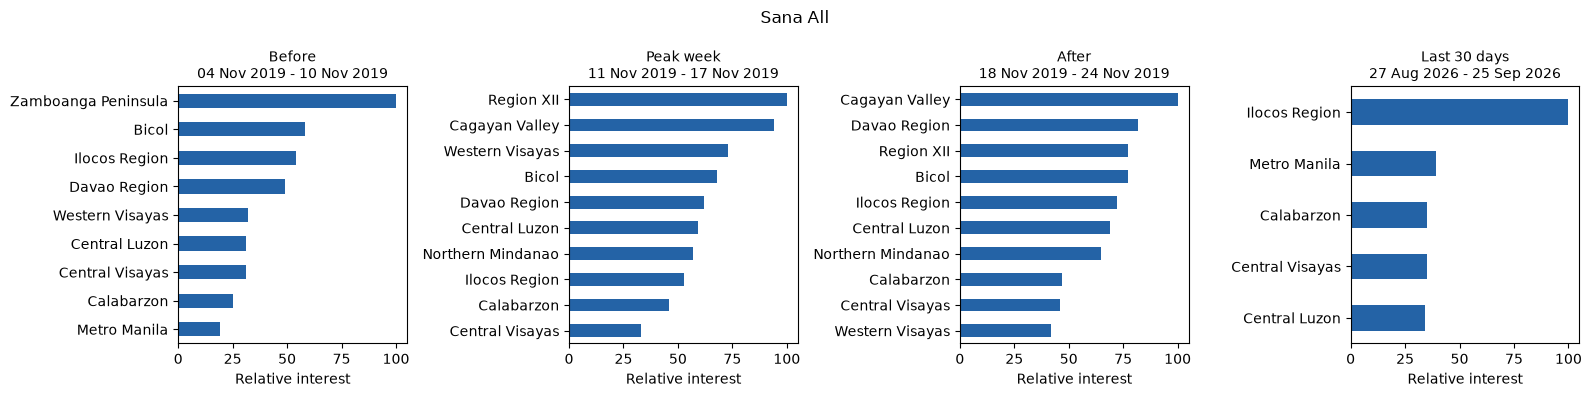

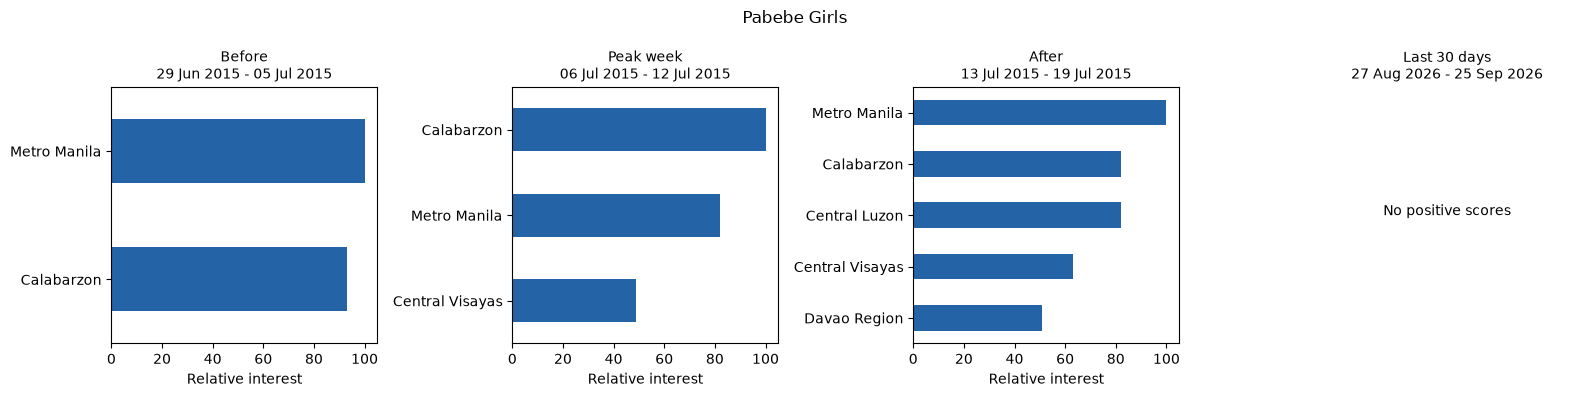

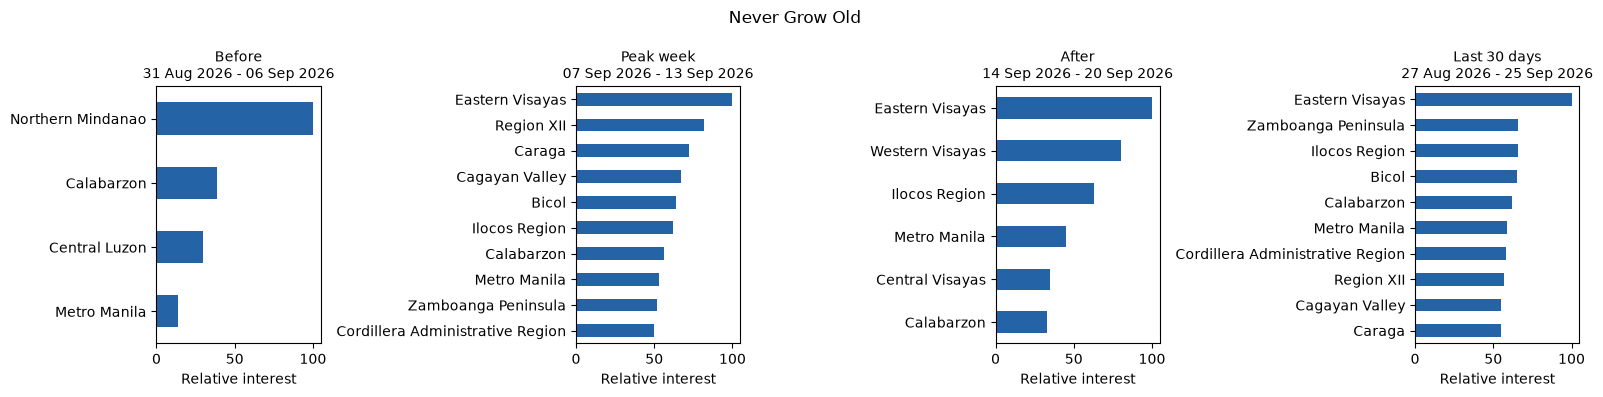

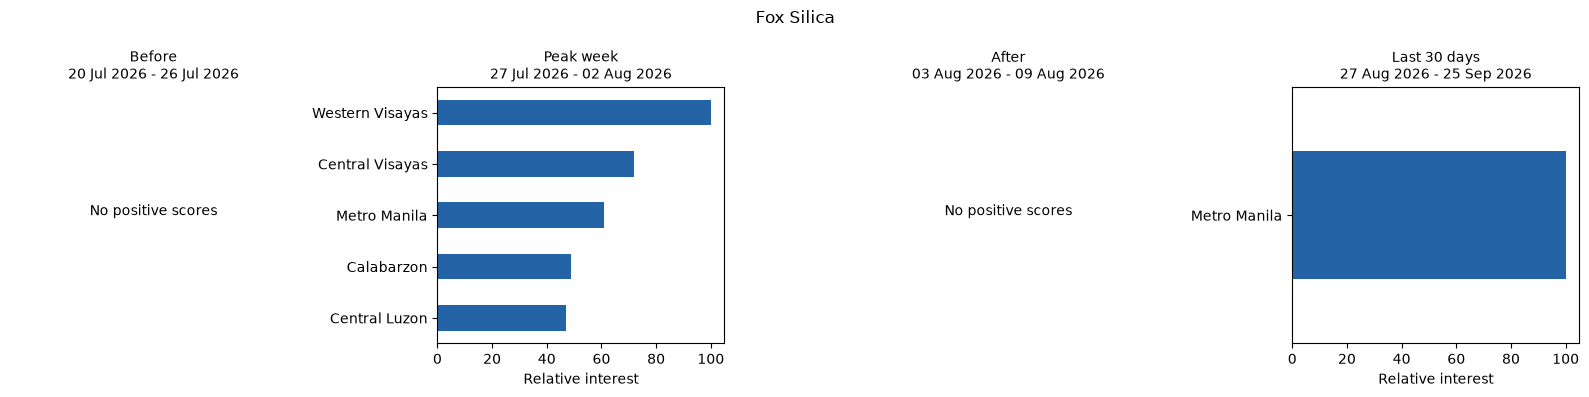

In [18]:
for trend in trends.itertuples(index=False):
    if trend.slug not in region_windows:
        continue

    windows = region_windows[trend.slug]
    fig, axes = plt.subplots(1, len(windows), figsize=(4 * len(windows), 4), squeeze=False)

    for ax, (label, start, end) in zip(axes[0], windows):
        ax.set_title(f"{label}\n{start:%d %b %Y} - {end:%d %b %Y}", fontsize=10)
        frame = region_data.get((trend.slug, label))
        if frame is None or frame.empty:
            ax.text(0.5, 0.5, "No regional data", ha="center", transform=ax.transAxes)
            ax.set_axis_off()
            continue

        scores = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
        top = scores.loc[(scores > 0) & (scores <= 100)].sort_values(ascending=False).head(10)
        if top.empty:
            ax.text(0.5, 0.5, "No positive scores", ha="center", transform=ax.transAxes)
            ax.set_axis_off()
        else:
            top.sort_values().plot.barh(ax=ax, color="#2463a6")
            ax.set(xlabel="Relative interest", ylabel="", xlim=(0, 105))

    fig.suptitle(trend.query)
    fig.tight_layout()
    plt.show()


## 7. What did we find?

Saved run, using data through **25 Sep 2026**:

| Trend | Peak-week mean | Next-week mean | Reading |
|---|---:|---:|---|
| Sana All | 68.9 | 74.9 | Interest stayed high after the peak day. |
| Pabebe Girls | 36.9 | 52.3 | Interest kept rising after the peak day. |
| Never Grow Old | 89.7 | 26.7 | The next week kept about 30% of peak-week interest. |
| Fox Silica | 25.4 | 0.0 | A short spike; check it against other sources. |

These are separate scales. Compare weeks within each term, not scores across terms.
The notes below update when you rerun; this table records the saved run.

### Notes from this run

Use the complete weeks above. The week containing the highest day need not have the highest weekly mean.


In [19]:
if changes.empty:
    print("No weekly findings yet. Load daily data and rerun the comparison.")
else:
    for row in changes.to_dict("records"):
        query = row["Trend"]
        rise = row["Before to peak (points)"]
        later = row["Peak to after (points)"]

        if pd.isna(rise):
            print(f"{query}: before-to-peak comparison needs two complete weeks.")
        elif rise > 0:
            print(f"{query}: peak-week mean rose {rise:.1f} points from the week before.")
        elif rise < 0:
            print(f"{query}: peak-week mean fell {abs(rise):.1f} points from the week before.")
        else:
            print(f"{query}: before and peak-week means were equal.")

        if pd.isna(later):
            print("  After-peak comparison needs two complete weeks.")
        elif later < 0:
            print(f"  The following week's mean fell {abs(later):.1f} points.")
        elif later > 0:
            print(f"  The following week's mean rose {later:.1f} points.")
        else:
            print("  The following week's mean stayed the same.")


Sana All: peak-week mean rose 12.4 points from the week before.
  The following week's mean rose 11.0 points.
Pabebe Girls: peak-week mean rose 24.7 points from the week before.
  The following week's mean rose 15.9 points.
Never Grow Old: peak-week mean rose 79.6 points from the week before.
  The following week's mean fell 62.6 points.
Fox Silica: peak-week mean rose 21.6 points from the week before.
  The following week's mean fell 21.6 points.


Predict the next period from the previous 12 periods with a small neural network.
Monthly input predicts monthly interest; daily input predicts daily interest.
At least 80 complete lag windows are required. The short daily histories will be
skipped with a reason, rather than forced into an unreliable training experiment.

Use chronological **60% train / 20% validation / 20% test** partitions. Select the
checkpoint using validation loss and compare test MAE against the last observed
value. Fixed division by 100 needs no fitted scaler. Missing or invalid observations
invalidate their lag windows; no interpolation reads future values. Request metadata
excludes unfinished final weeks/months. Without metadata, supply completed periods.

Evaluation predicts one step at a time using already observed past test values.
It does not forecast the entire holdout from its first day. Use expanding-window
validation before claiming a reliable improvement, and do not tune settings on test
scores.

In [20]:
import copy
import numpy as np

def load_series(path, column=None):
    """Read a cached single-query CSV; use metadata to exclude unfinished periods."""
    path = Path(path)
    frame = pd.read_csv(path, index_col=0)
    frame.index = pd.to_datetime(frame.index, errors="raise")
    partial = pd.Series(False, index=frame.index)
    if "isPartial" in frame:
        partial = frame.pop("isPartial").astype(str).str.lower().isin(["true", "1"])
    if column is None:
        if len(frame.columns) != 1:
            raise ValueError("Pass column= for a multi-term CSV.")
        column = frame.columns[0]
    series = pd.to_numeric(frame[column].astype(str).str.strip().replace(
        {"<1": "0.5", "< 1": "0.5"}), errors="coerce")
    series.loc[partial] = np.nan
    series = series.sort_index()
    if series.index.has_duplicates or len(series) < 3:
        raise ValueError("Need at least three unique date rows.")
    freq = pd.infer_freq(series.index)
    if freq is None:
        raise ValueError("CSV must have regular daily, weekly, or monthly dates; retain missing rows as NaN.")
    offset = pd.tseries.frequencies.to_offset(freq)
    if not (freq == "D" or freq.startswith("W-") or freq == "MS"):
        raise ValueError(f"Unsupported frequency {freq}; expected daily, weekly, or month-start.")
    metadata_path = path.with_suffix(".json")
    if metadata_path.exists():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata.get("kind", "time") != "time":
            raise ValueError("Regional snapshots are not temporal training data.")
        window = metadata.get("window", "").split()
        if len(window) == 2:
            start, end = map(pd.Timestamp, window)
            series = series.loc[start:end]
            # A monthly/weekly row describes a whole period, not just its first day.
            complete = series.index + offset - pd.Timedelta(days=1) <= end
            series = series.loc[complete]
    return series


def make_windows(series, lookback=12):
    if lookback < 2:
        raise ValueError("lookback must be at least 2.")
    if not isinstance(series.index, pd.DatetimeIndex) or series.index.has_duplicates:
        raise ValueError("Expected a unique DatetimeIndex.")
    series = series.sort_index()
    if pd.infer_freq(series.index) is None:
        raise ValueError("Use a regular date grid; missing observations must stay NaN.")
    values = series.to_numpy(dtype=np.float32)
    x, y, dates = [], [], []
    for target in range(lookback, len(values)):
        window = values[target - lookback:target + 1]
        if np.isfinite(window).all() and ((window >= 0) & (window <= 100)).all():
            x.append(window[:-1] / 100.0)
            y.append(window[-1] / 100.0)
            dates.append(series.index[target])
    if not x:
        raise ValueError("No complete valid lag windows.")
    return np.asarray(x), np.asarray(y), pd.DatetimeIndex(dates)


def train_forecaster(series, lookback=12, epochs=300, seed=42):
    device = require_cuda()
    if epochs < 1:
        raise ValueError("epochs must be positive.")
    x, y, dates = make_windows(series, lookback)
    if len(y) < 80:
        raise ValueError(f"Only {len(y)} complete windows; need at least 80. Collect more history.")
    train_end, val_end = int(len(y) * 0.6), int(len(y) * 0.8)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Fixed /100 scaling needs no fitted statistics from future observations.
    inputs = torch.as_tensor(x, device=device)
    targets = torch.as_tensor(y, device=device)
    model = torch.nn.Sequential(torch.nn.Linear(lookback, 16), torch.nn.ReLU(),
                                torch.nn.Linear(16, 1)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.003, weight_decay=0.01)
    best_loss, best_state, stale, best_epoch = float("inf"), None, 0, 0
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = torch.nn.functional.mse_loss(model(inputs[:train_end]).squeeze(-1), targets[:train_end])
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            validation = torch.nn.functional.mse_loss(
                model(inputs[train_end:val_end]).squeeze(-1), targets[train_end:val_end]).item()
        if not np.isfinite(validation):
            raise RuntimeError("Non-finite validation loss.")
        if validation < best_loss:
            best_loss, best_state = validation, copy.deepcopy(model.state_dict())
            stale, best_epoch = 0, epoch + 1
        else:
            stale += 1
            if stale >= 30:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        predicted = model(inputs[val_end:]).squeeze(-1).clamp(0, 1).cpu().numpy() * 100
    actual, baseline = y[val_end:] * 100, x[val_end:, -1] * 100
    predictions = pd.DataFrame({"actual": actual, "predicted": predicted,
                                "last_value_baseline": baseline}, index=dates[val_end:])
    predictions.index.name = "date"
    model_mae = float(np.abs(actual - predicted).mean())
    baseline_mae = float(np.abs(actual - baseline).mean())
    report = {
        "device": str(next(model.parameters()).device), "gpu": torch.cuda.get_device_name(device),
        "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
        "seed": seed, "lookback": lookback, "best_epoch": best_epoch,
        "train_windows": train_end, "validation_windows": val_end - train_end,
        "test_windows": len(y) - val_end, "train_last_target": str(dates[train_end - 1]),
        "validation_first_target": str(dates[train_end]), "test_first_target": str(dates[val_end]),
        "test_last_target": str(dates[-1]), "model_mae_index_points": model_mae,
        "baseline_mae_index_points": baseline_mae, "beats_baseline": model_mae < baseline_mae,
        "evaluation": "one-step walk-forward with observed past lags; no test-set fitting",
    }
    return model, report, predictions

In [21]:
# Settings: change these before running the experiment.
ML_LOOKBACK = 12
ML_EPOCHS = 300
ML_SEED = 42
ML_SAVE_ARTIFACTS = False  # Results always remain visible in this notebook.
ML_ARTIFACT_DIR = Path("artifacts")

# Uses current full-history cache filenames when available; otherwise the older caches.
ml_terms = [
    ("sana_all", "Sana All", "2018-01-01"),
    ("pabebe_girls", "Pabebe Girls", "2015-01-01"),
    ("never_grow_old", "Never Grow Old", "2026-08-15"),
    ("fox_silica", "Fox Silica", "2026-07-15"),
]
ml_end_date = globals().get("END_DATE", "2026-09-25")
ml_series = {}
ml_sources = []
for slug, query, start in ml_terms:
    current_path = Path("data/raw") / f"{slug}_time_{start}_{ml_end_date}.csv"
    legacy_path = Path("data/raw") / f"{slug}.csv"
    source_path = current_path if current_path.exists() else legacy_path
    if not source_path.exists():
        print(f"{query}: no full-history cache. Run the data section or add a matching export.")
        continue
    try:
        series = load_series(source_path)
    except ValueError as error:
        print(f"{query}: skipped ({error})")
        continue
    ml_series[slug] = series
    metadata_path = source_path.with_suffix(".json")
    metadata = json.loads(metadata_path.read_text(encoding="utf-8")) if metadata_path.exists() else {}
    ml_sources.append({"Trend": query, "CSV": str(source_path),
                       "Request window": metadata.get("window", "unknown; use completed periods only"),
                       "Completed rows": len(series), "Frequency": pd.infer_freq(series.index)})
display(pd.DataFrame(ml_sources))

,Trend,CSV,Request window,Completed rows,Frequency
0,Sana All,data\raw\sana_all_time_2018-01-01_2026-09-25.csv,2018-01-01 2026-09-25,104,MS
1,Pabebe Girls,data\raw\pabebe_girls_time_2015-01-01_2026-09-...,2015-01-01 2026-09-25,140,MS
2,Never Grow Old,data\raw\never_grow_old_time_2026-08-15_2026-0...,2026-08-15 2026-09-25,42,D
3,Fox Silica,data\raw\fox_silica_time_2026-07-15_2026-09-25...,2026-07-15 2026-09-25,73,D


In [22]:
ml_results = {}
ml_summary_rows = []
for slug, series in ml_series.items():
    try:
        model, metrics, predictions = train_forecaster(
            series, lookback=ML_LOOKBACK, epochs=ML_EPOCHS, seed=ML_SEED)
    except ValueError as error:
        print(f"{slug}: skipped ({error})")
        continue
    ml_results[slug] = {"model": model, "metrics": metrics, "predictions": predictions}
    ml_summary_rows.append({"Trend": series.name, "Device": metrics["device"],
                            "Test periods": metrics["test_windows"],
                            "Model MAE": metrics["model_mae_index_points"],
                            "Last-value MAE": metrics["baseline_mae_index_points"],
                            "Beats baseline": metrics["beats_baseline"]})
    if ML_SAVE_ARTIFACTS:
        output = ML_ARTIFACT_DIR / slug
        output.mkdir(parents=True, exist_ok=True)
        torch.save({"state_dict": model.state_dict(), "report": metrics}, output / "model.pt")
        predictions.to_csv(output / "test_predictions.csv")
        (output / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
ml_summary = pd.DataFrame(ml_summary_rows)
display(ml_summary.round(3))
if ml_summary.empty:
    print("No eligible training series. Collect more complete full-history observations.")

never_grow_old: skipped (Only 30 complete windows; need at least 80. Collect more history.)
fox_silica: skipped (Only 61 complete windows; need at least 80. Collect more history.)


,Trend,Device,Test periods,Model MAE,Last-value MAE,Beats baseline
0,Sana All,cuda:0,19,0.518,0.632,True
1,Pabebe Girls,cuda:0,26,0.012,0.000,False


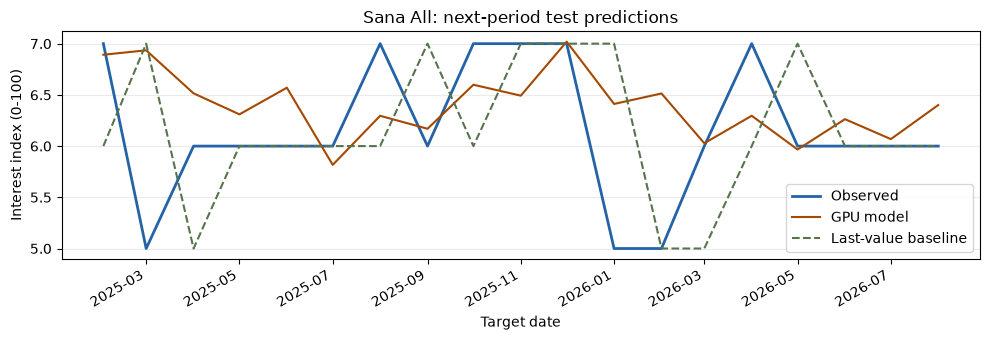

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    12
best_epoch                                                                  60
train_windows                                                               55
validation_windows                                                          18
test_windows                                                                19
train_last_target                                          2023-07-01 00:00:00
validation_first_target                                    2023-08-01 00:00:00
test_first_target                                   

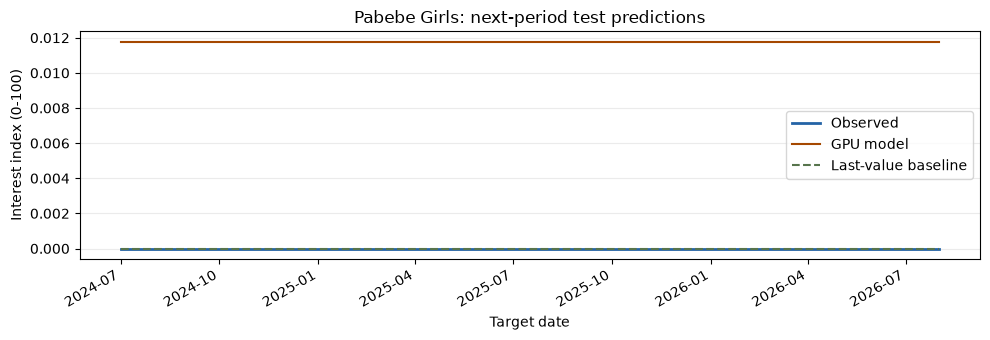

device                                                                  cuda:0
gpu                                         NVIDIA GeForce RTX 5050 Laptop GPU
torch                                                             2.13.0+cu130
cuda_runtime                                                              13.0
seed                                                                        42
lookback                                                                    12
best_epoch                                                                  75
train_windows                                                               76
validation_windows                                                          26
test_windows                                                                26
train_last_target                                          2022-04-01 00:00:00
validation_first_target                                    2022-05-01 00:00:00
test_first_target                                   

In [23]:
for slug, result in ml_results.items():
    predictions = result["predictions"]
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(predictions.index, predictions["actual"], label="Observed", color="#2463a6", linewidth=2)
    ax.plot(predictions.index, predictions["predicted"], label="GPU model", color="#a54800")
    ax.plot(predictions.index, predictions["last_value_baseline"], label="Last-value baseline",
            color="#57744c", linestyle="--")
    ax.set(title=f"{ml_series[slug].name}: next-period test predictions",
           xlabel="Target date", ylabel="Interest index (0-100)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
    display(pd.Series(result["metrics"], name="Evaluation details"))

### Reading the experiment

Compare each model with its own last-value baseline, within that request's scale.
The initial cached-data run gave Sana All MAE 0.583 versus baseline 0.632, while
Pabebe Girls gave 0.035 versus baseline 0.000. A small improvement on one holdout
does not establish forecasting skill; an all-zero holdout can favor a trivial predictor.
The live table and charts above update when you rerun with different data.

The next useful experiment is unusual-rise detection using past-only forecast errors,
with alert thresholds selected on validation history. Collect more terms, repeated
pulls, and consistent histories before increasing model size.